In [1]:
import common as cm
import os
import numpy as np
import pandas as pd

In [2]:
# Load GLM top-N results (long format: icd, prs_num, n_prs_used, auc)
aou_topn = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "increase_prs_num", "aou_glm_topN_result.csv"))
ukb_topn = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "increase_prs_num", "ukb_glm_topN_result.csv"))

# Load N = 10 GLM results from the main ensemble run
# NOTE: assumes columns "icd" and "auc"; rename if different
aou_glm10 = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "aou_glm_result.csv"))
ukb_glm10 = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "ukb_glm_result.csv"))

# Reshape N = 10 results into the same long format and append
aou_glm10_long = aou_glm10[["icd", "auc"]].assign(prs_num=10)
ukb_glm10_long = ukb_glm10[["icd", "auc"]].assign(prs_num=10)
aou_long = pd.concat([aou_topn[aou_topn["prs_num"] != 10][["icd", "prs_num", "auc"]], aou_glm10_long], ignore_index=True)
ukb_long = pd.concat([ukb_topn[ukb_topn["prs_num"] != 10][["icd", "prs_num", "auc"]], ukb_glm10_long], ignore_index=True)

# Pivot to wide format: one row per ICD, one column per N (auc_5, auc_10, ...)
aou_data_temp = aou_long.pivot(index="icd", columns="prs_num", values="auc")
ukb_data_temp = ukb_long.pivot(index="icd", columns="prs_num", values="auc")
aou_data_temp.columns = [f"auc_{n}" for n in aou_data_temp.columns]
ukb_data_temp.columns = [f"auc_{n}" for n in ukb_data_temp.columns]
aou_data_temp = aou_data_temp.reset_index()
ukb_data_temp = ukb_data_temp.reset_index()

# Number of candidate PRS and the column-name template for each N
glm_nums = [5, 10, 20, 50, 100, 200]
col_template = "auc_{}"

# Report missing values per N before filtering
print("AoU missing per N:", aou_data_temp[[col_template.format(n) for n in glm_nums]].isna().sum().to_dict())
print("UKB missing per N:", ukb_data_temp[[col_template.format(n) for n in glm_nums]].isna().sum().to_dict())

# Keep only traits with results at every N so all points use the same trait set
aou_data_temp = aou_data_temp.dropna(subset=[col_template.format(n) for n in glm_nums])
ukb_data_temp = ukb_data_temp.dropna(subset=[col_template.format(n) for n in glm_nums])
print(f"Traits kept: AoU {len(aou_data_temp)}, UKB {len(ukb_data_temp)}")

AoU missing per N: {'auc_5': 0, 'auc_10': 0, 'auc_20': 0, 'auc_50': 0, 'auc_100': 0, 'auc_200': 0}
UKB missing per N: {'auc_5': 0, 'auc_10': 0, 'auc_20': 0, 'auc_50': 0, 'auc_100': 0, 'auc_200': 0}
Traits kept: AoU 367, UKB 325


In [3]:
# Restrict both cohorts to the ICDs present in both (same trait set for AoU and UKB)
shared_icds = set(aou_data_temp["icd"]) & set(ukb_data_temp["icd"])
aou_data_temp = aou_data_temp[aou_data_temp["icd"].isin(shared_icds)].reset_index(drop=True)
ukb_data_temp = ukb_data_temp[ukb_data_temp["icd"].isin(shared_icds)].reset_index(drop=True)
print(f"Shared traits: {len(shared_icds)} (AoU {len(aou_data_temp)}, UKB {len(ukb_data_temp)})")

Shared traits: 325 (AoU 325, UKB 325)


In [4]:
import os

# Training-half case count for each trait, from the training ranking files
n_case_train = {}
for icd in aou_data_temp["icd"]:
    p = os.path.join(cm.ROOT_PATH, "prs_ranking", "AoU_training", f"{icd}.csv")
    if os.path.exists(p):
        n_case_train[icd] = pd.read_csv(p, nrows=1)["n_cases"].iloc[0]
aou_data_temp["n_case_train"] = aou_data_temp["icd"].map(n_case_train)

# Keep a copy of the full table, then restrict to traits with >= 1000 training cases
aou_data_temp_all = aou_data_temp.copy()
aou_data_temp = aou_data_temp_all[aou_data_temp_all["n_case_train"] >= 500].copy()

ukb_data_temp_all = ukb_data_temp.copy()
ukb_data_temp = ukb_data_temp_all[ukb_data_temp_all["icd"].isin(aou_data_temp["icd"])].copy()
print("Traits with >= 1000 training cases:", len(aou_data_temp), "of", len(aou_data_temp_all))
print("Traits with >= 1000 training cases:", len(ukb_data_temp), "of", len(ukb_data_temp_all))

Traits with >= 1000 training cases: 325 of 325
Traits with >= 1000 training cases: 325 of 325


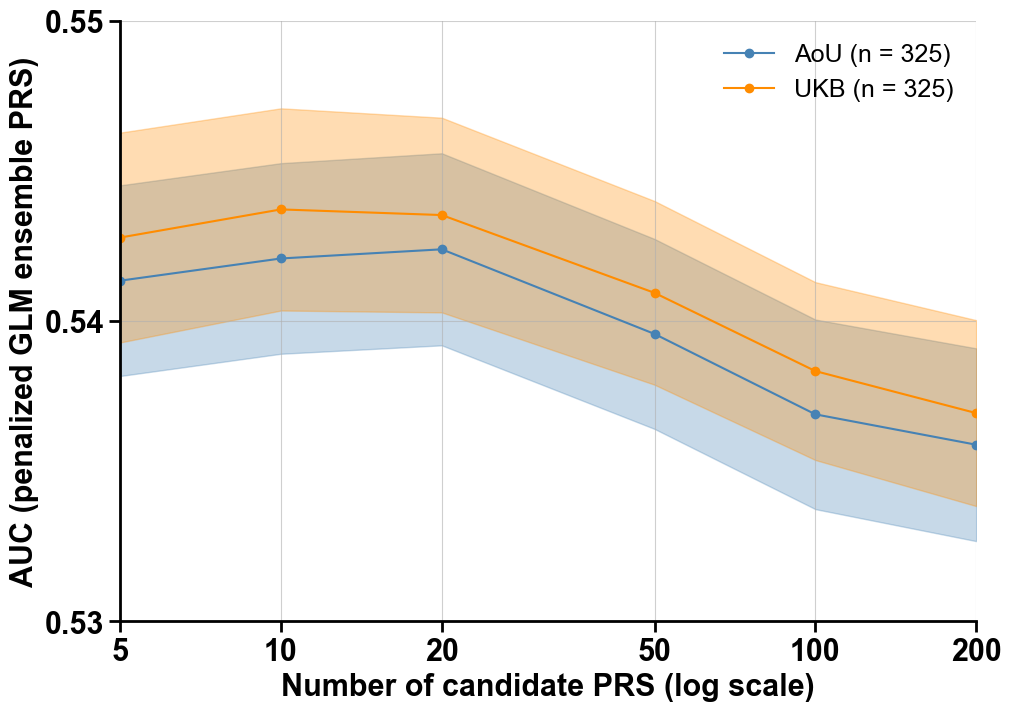

In [5]:

import matplotlib
import matplotlib.pyplot as plt

# Set the font before creating the figure
matplotlib.rcParams["font.family"] = "Arial"

# Mean AUC and 95% CI half-width (1.96 * SEM) across traits for each N
glm_aou_means = np.array([aou_data_temp[col_template.format(n)].mean() for n in glm_nums])
glm_ukb_means = np.array([ukb_data_temp[col_template.format(n)].mean() for n in glm_nums])
glm_aou_ci = np.array([1.96 * aou_data_temp[col_template.format(n)].sem() for n in glm_nums])
glm_ukb_ci = np.array([1.96 * ukb_data_temp[col_template.format(n)].sem() for n in glm_nums])

# Create figure
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")

# AoU line with 95% CI band
ax.plot(glm_nums, glm_aou_means, marker="o", color="steelblue", label=f"AoU (n = {len(aou_data_temp)})")
ax.fill_between(glm_nums, glm_aou_means - glm_aou_ci, glm_aou_means + glm_aou_ci,
                color="steelblue", alpha=0.3)

# UKB line with 95% CI band
ax.plot(glm_nums, glm_ukb_means, marker="o", color="darkorange", label=f"UKB (n = {len(ukb_data_temp)})")
ax.fill_between(glm_nums, glm_ukb_means - glm_ukb_ci, glm_ukb_means + glm_ukb_ci,
                color="darkorange", alpha=0.3)

# Fixed y range for the figure
y_lo, y_hi = 0.53, 0.55
ax.set_ylim(y_lo, y_hi)
ax.set_yticks(np.round(np.arange(y_lo, y_hi + 1e-9, 0.01), 2))

# Log-scaled x axis with the tested N values as ticks
ax.set_xscale("log")
ax.set_xlim(glm_nums[0], glm_nums[-1])
ax.set_xticks(glm_nums)
ax.set_xticklabels(glm_nums)
ax.minorticks_off()

# Spines, grid and tick styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2)
ax.spines["bottom"].set_linewidth(2)
ax.grid(which="major", alpha=0.6)
ax.tick_params(axis="both", which="major", labelsize=22, length=8, width=2)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

# Labels and legend
ax.set_xlabel("Number of candidate PRS (log scale)", fontsize=22, fontweight="bold")
ax.set_ylabel("AUC (penalized GLM ensemble PRS)", fontsize=22, fontweight="bold")
ax.legend(fontsize=18, frameon=False)

plt.show()


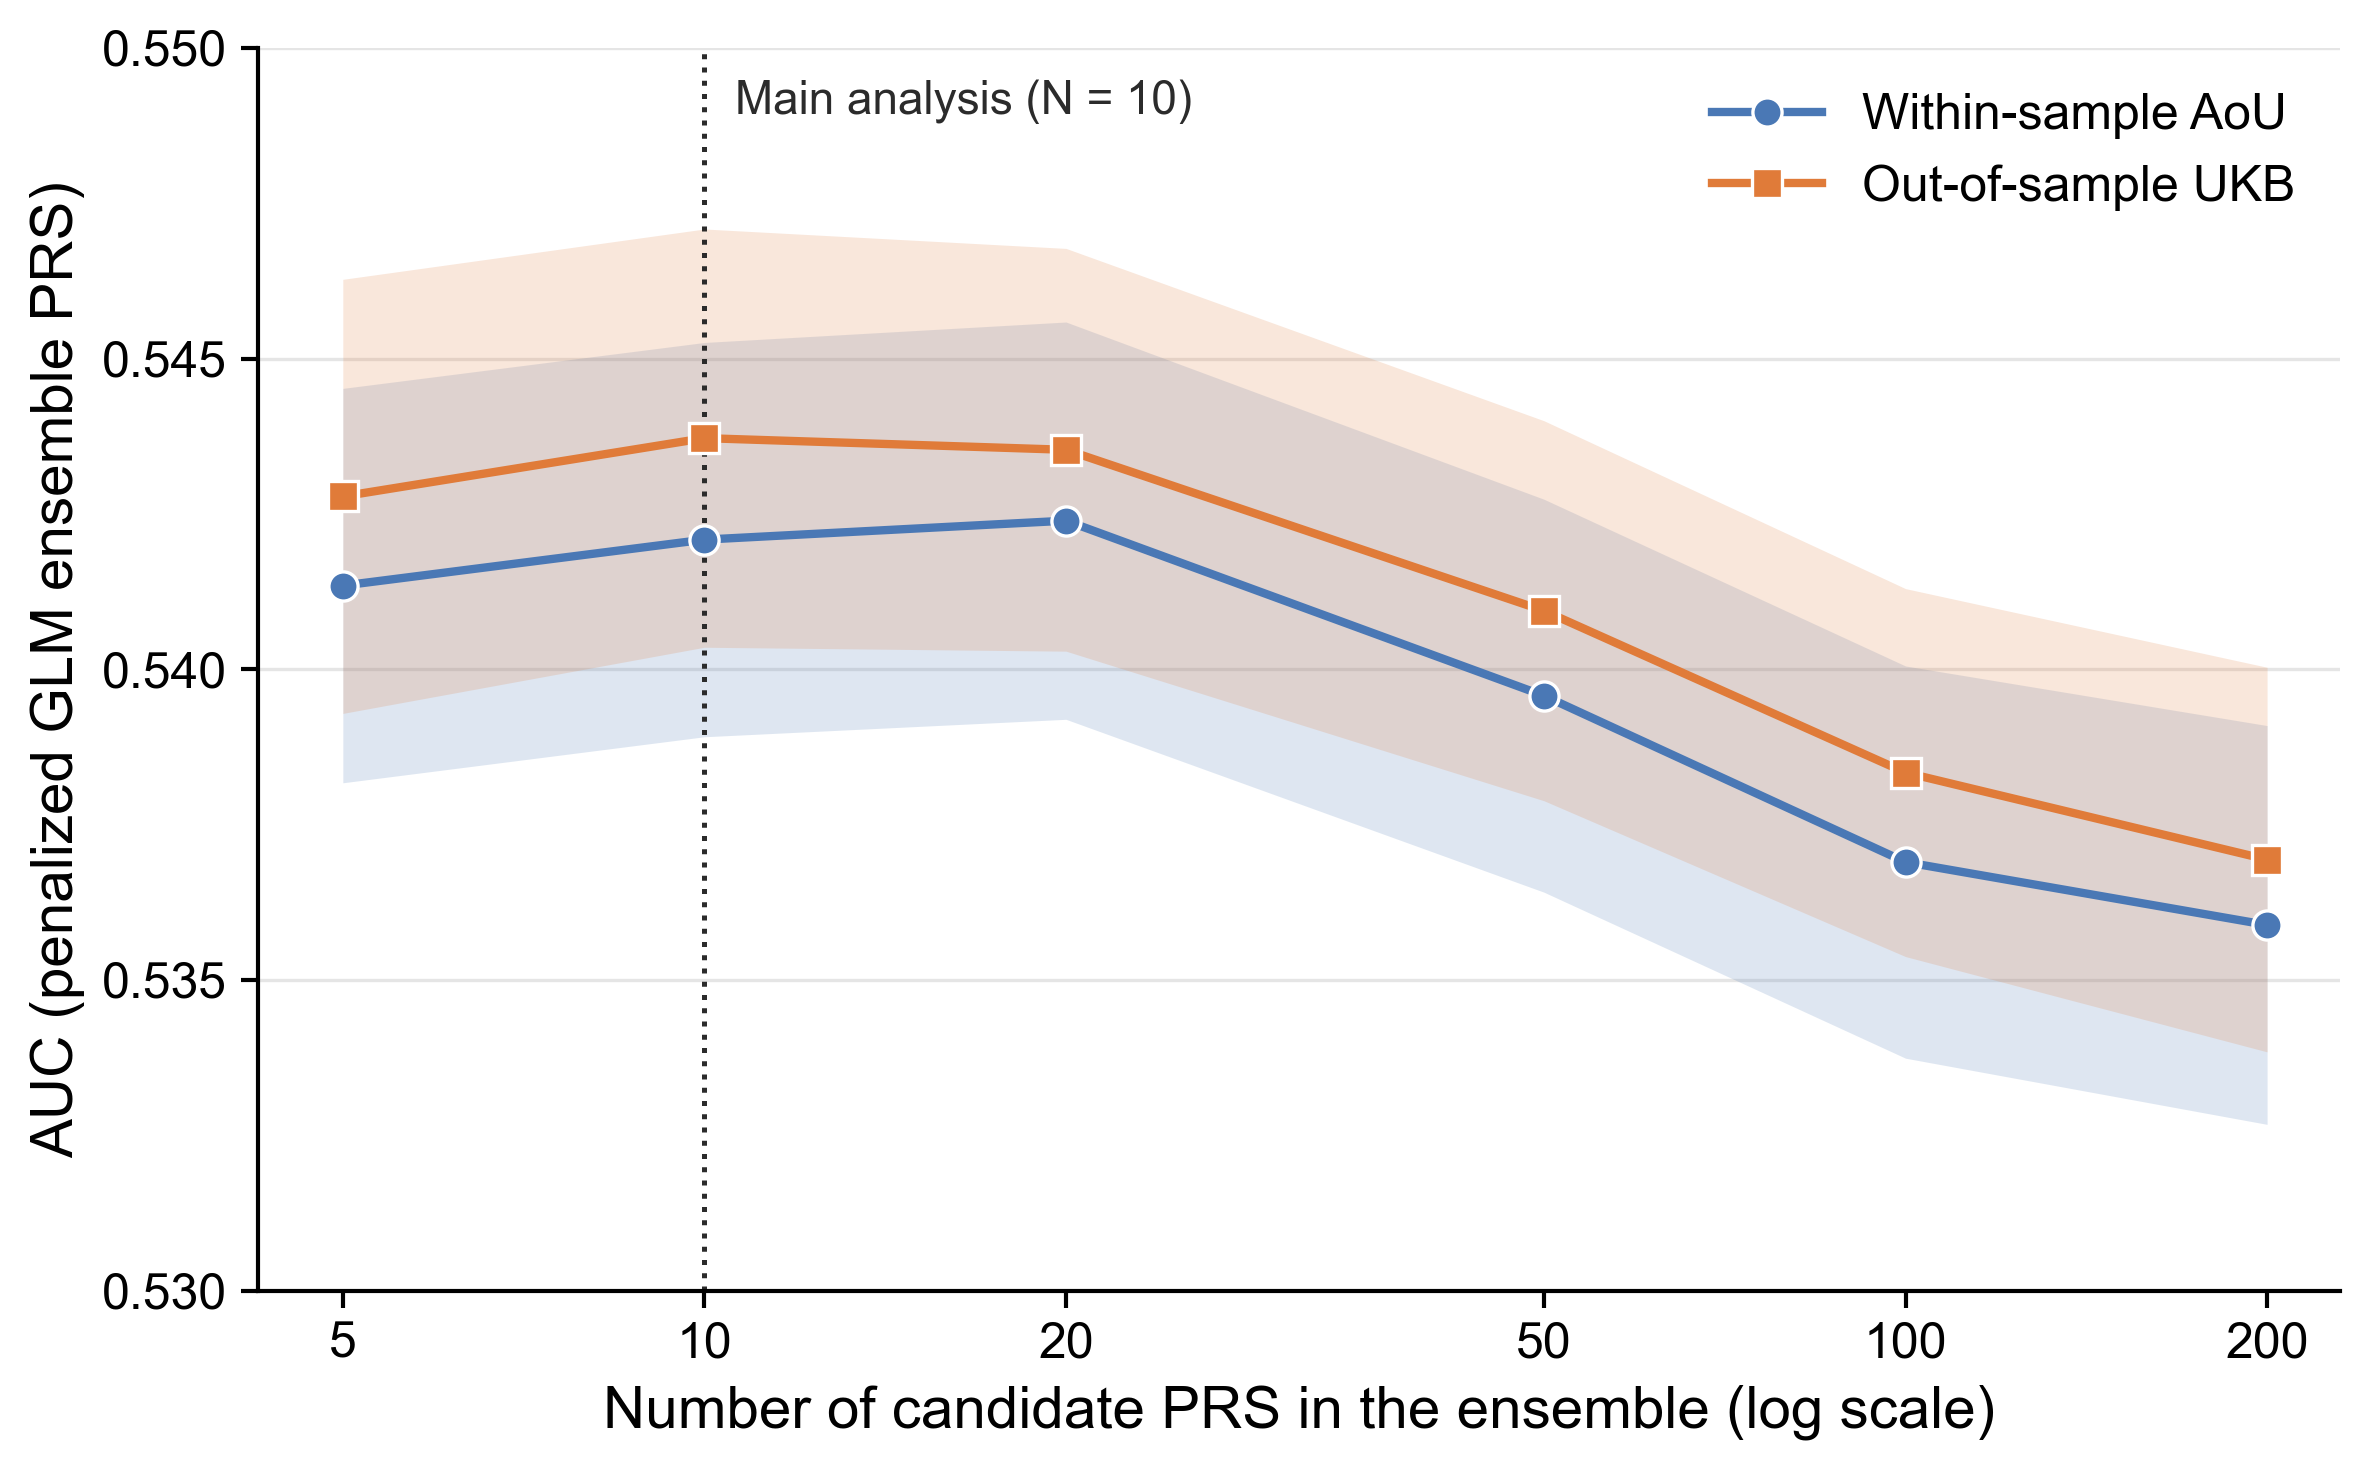

In [6]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

### Style matched to the shared-candidate bar chart (Arial, thin spines, light y grid) ###
matplotlib.rcParams.update({
    "font.family": "Arial", "pdf.fonttype": 42,
    "figure.dpi": 300, "savefig.dpi": 600,
})

### Cohort colors: same as Fig 1a schematic ###
aou_color, ukb_color = "#4A78B5", "#E07B39"

### Mean AUC and 95% CI half-width (1.96 * SEM) across traits for each N ###
glm_aou_means = np.array([aou_data_temp[col_template.format(n)].mean() for n in glm_nums])
glm_ukb_means = np.array([ukb_data_temp[col_template.format(n)].mean() for n in glm_nums])
glm_aou_ci = np.array([1.96 * aou_data_temp[col_template.format(n)].sem() for n in glm_nums])
glm_ukb_ci = np.array([1.96 * ukb_data_temp[col_template.format(n)].sem() for n in glm_nums])

### Figure (same canvas size as the bar chart) ###
fig, ax = plt.subplots(figsize=(8, 5))

# AoU: light CI band underneath, line with white-edged markers on top
ax.fill_between(glm_nums, glm_aou_means - glm_aou_ci, glm_aou_means + glm_aou_ci,
                color=aou_color, alpha=0.18, linewidth=0, zorder=1)
ax.plot(glm_nums, glm_aou_means, "o-", color=aou_color, lw=2, ms=7,
        markeredgecolor="white", markeredgewidth=0.8, zorder=3,
        label=f"Within-sample AoU")

# UKB: same encoding, square markers for redundancy beyond color
ax.fill_between(glm_nums, glm_ukb_means - glm_ukb_ci, glm_ukb_means + glm_ukb_ci,
                color=ukb_color, alpha=0.18, linewidth=0, zorder=1)
ax.plot(glm_nums, glm_ukb_means, "s-", color=ukb_color, lw=2, ms=7,
        markeredgecolor="white", markeredgewidth=0.8, zorder=3,
        label=f"Out-of-sample UKB")

# Mark the N used in the main analysis (top-10)
ax.axvline(10, color="#2B2B2B", lw=1.2, ls=":", zorder=2)
ax.text(10 * 1.06, 0.5495, "Main analysis (N = 10)", ha="left", va="top", fontsize=11, color="#2B2B2B")

# Y axis: fixed range, 3-decimal ticks every 0.005
ax.set_ylim(0.53, 0.55)
ax.set_yticks(np.arange(0.530, 0.5501, 0.005))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))

# X axis: log scale with tested N values as ticks
ax.set_xscale("log")
ax.set_xlim(glm_nums[0] * 0.85, glm_nums[-1] * 1.15)
ax.set_xticks(glm_nums)
ax.set_xticklabels(glm_nums)
ax.minorticks_off()

# Labels and legend (same font sizes as the bar chart)
ax.set_xlabel("Number of candidate PRS in the ensemble (log scale)", fontsize=14)
ax.set_ylabel("AUC (penalized GLM ensemble PRS)", fontsize=14)
ax.tick_params(axis="both", labelsize=12, width=1, length=4)
ax.legend(frameon=False, loc="upper right", fontsize=12, handlelength=2.2)

# Clean spines and light horizontal grid only
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_linewidth(1)
ax.yaxis.grid(True, color="#E5E5E5", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

### Save vector PDF for the paper and PNG for slides ###
fig.tight_layout()
plt.show()

In [7]:
# Summary table of mean AUC and 95% CI per N for both cohorts (text anchors for Fig. 2c)
anchor = pd.DataFrame({
    "N": glm_nums,
    "aou_mean": glm_aou_means,
    "aou_lo": glm_aou_means - glm_aou_ci,
    "aou_hi": glm_aou_means + glm_aou_ci,
    "ukb_mean": glm_ukb_means,
    "ukb_lo": glm_ukb_means - glm_ukb_ci,
    "ukb_hi": glm_ukb_means + glm_ukb_ci,
}).round(3)
print(f"n traits: AoU {len(aou_data_temp)}, UKB {len(ukb_data_temp)}")
print(anchor.to_string(index=False))

# N with the highest mean AUC in each cohort
print("Peak N: AoU", glm_nums[int(np.argmax(glm_aou_means))],
      "| UKB", glm_nums[int(np.argmax(glm_ukb_means))])

# Change from N = 10 to N = 200 (size of the decline)
i10, i200 = glm_nums.index(10), glm_nums.index(200)
print(f"Delta 10 -> 200: AoU {glm_aou_means[i200] - glm_aou_means[i10]:+.4f}, "
      f"UKB {glm_ukb_means[i200] - glm_ukb_means[i10]:+.4f}")

# Paired test, top 10 vs top 20 and top 10 vs top 200, on the same traits (supports "comparable" / "declined")
from scipy.stats import wilcoxon
for name, df in [("AoU", aou_data_temp), ("UKB", ukb_data_temp)]:
    p_20 = wilcoxon(df["auc_10"], df["auc_20"]).pvalue
    p_200 = wilcoxon(df["auc_10"], df["auc_200"]).pvalue
    print(f"{name}: 10 vs 20 p = {p_20:.2e} | 10 vs 200 p = {p_200:.2e}")

# Fraction of traits where top 10 beats top 200 (an intuitive per-trait summary)
for name, df in [("AoU", aou_data_temp), ("UKB", ukb_data_temp)]:
    print(f"{name}: top 10 > top 200 in {(df['auc_10'] > df['auc_200']).mean():.1%} of traits")

n traits: AoU 325, UKB 325
  N  aou_mean  aou_lo  aou_hi  ukb_mean  ukb_lo  ukb_hi
  5     0.541   0.538   0.545     0.543   0.539   0.546
 10     0.542   0.539   0.545     0.544   0.540   0.547
 20     0.542   0.539   0.546     0.544   0.540   0.547
 50     0.540   0.536   0.543     0.541   0.538   0.544
100     0.537   0.534   0.540     0.538   0.535   0.541
200     0.536   0.533   0.539     0.537   0.534   0.540
Peak N: AoU 20 | UKB 10
Delta 10 -> 200: AoU -0.0062, UKB -0.0068
AoU: 10 vs 20 p = 1.73e-01 | 10 vs 200 p = 6.80e-24
UKB: 10 vs 20 p = 8.94e-01 | 10 vs 200 p = 4.03e-23
AoU: top 10 > top 200 in 73.2% of traits
UKB: top 10 > top 200 in 74.2% of traits
